## **Problem Statement**

### Business Context

The prices of the stocks of companies listed under a global exchange are influenced by a variety of factors, with the company's financial performance, innovations and collaborations, and market sentiment being factors that play a significant role. News and media reports can rapidly affect investor perceptions and, consequently, stock prices in the highly competitive financial industry. With the sheer volume of news and opinions from a wide variety of sources, investors and financial analysts often struggle to stay updated and accurately interpret its impact on the market. As a result, investment firms need sophisticated tools to analyze market sentiment and integrate this information into their investment strategies.

### Problem Definition

With an ever-rising number of news articles and opinions, an investment startup aims to leverage artificial intelligence to address the challenge of interpreting stock-related news and its impact on stock prices. They have collected historical daily news for a specific company listed under NASDAQ, along with data on its daily stock price and trade volumes.

As a member of the Data Science and AI team in the startup, you have been tasked with analyzing the data, developing an AI-driven sentiment analysis system that will automatically process and analyze news articles to gauge market sentiment, and summarizing the news at a weekly level to enhance the accuracy of their stock price predictions and optimize investment strategies. This will empower their financial analysts with actionable insights, leading to more informed investment decisions and improved client outcomes.

### Data Dictionary

* `Date` : The date the news was released
* `News` : The content of news articles that could potentially affect the company's stock price
* `Open` : The stock price (in \$) at the beginning of the day
* `High` : The highest stock price (in \$) reached during the day
* `Low` :  The lowest stock price (in \$) reached during the day
* `Close` : The adjusted stock price (in \$) at the end of the day
* `Volume` : The number of shares traded during the day
* `Label` : The sentiment polarity of the news content
    * 1: positive
    * 0: neutral
    * -1: negative

## **Please read the instructions carefully before starting the project.**

**Note**: If the free-tier GPU of Google Colab is not accessible (due to unavailability or exhaustion of daily limit or other reasons), the following steps can be taken:

1. Wait for 12-24 hours until the GPU is accessible again or the daily usage limits are reset.

2. Switch to a different Google account and resume working on the project from there.

3. Try using the CPU runtime:
    - To use the CPU runtime, click on *Runtime* => *Change runtime type* => *CPU* => *Save*
    - One can also click on the *Continue without GPU* option to switch to a CPU runtime (kindly refer to the snapshot below)
    - The instructions for running the code on the CPU are provided in the respective sections of the notebook.

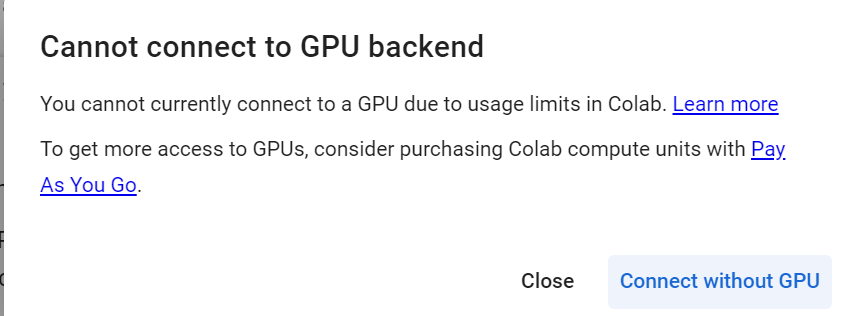

## **Installing and Importing Necessary Libraries**

In [ ]:
# installing the sentence-transformers and gensim libraries for word embeddings
!pip install -U sentence-transformers gensim transformers tqdm -q
!pip install -U sentence-transformers -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 2.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.8/268.8 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 81.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.6/78.6 kB 6.0 MB/s eta 0:00:00


In [ ]:
# to read and manipulate the data
import pandas as pd
import numpy as np
pd.set_option('max_colwidth', None)    # setting column to the maximum column width as per the data

# to visualise data
import matplotlib.pyplot as plt
import seaborn as sns

# to use regular expressions for manipulating text data
import re

# to load the natural language toolkit
import nltk
nltk.download('stopwords')    # loading the stopwords
nltk.download('wordnet')    # loading the wordnet module that is used in stemming

# to remove common stop words
from nltk.corpus import stopwords

# to perform stemming
from nltk.stem.porter import PorterStemmer

# To encode the target variable
from sklearn.preprocessing import LabelEncoder

# To import Word2Vec
from gensim.models import Word2Vec

# To tune the model
from sklearn.model_selection import GridSearchCV

# Converting the Stanford GloVe model vector format to word2vec
from gensim.scripts.glove2word2vec import glove2word2vec
from gensim.models import KeyedVectors

# To split data into train and test sets
from sklearn.model_selection import train_test_split

# To build a Random Forest model
from sklearn.ensemble import RandomForestClassifier

# To compute metrics to evaluate the model
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, precision_score, recall_score, classification_report

# to compute distances
from scipy.spatial.distance import cdist, pdist
from sklearn.metrics import silhouette_score

# importing the PyTorch Deep Learning library
import torch

# to import the model
from sentence_transformers import SentenceTransformer

# to cluster the data
from sklearn.cluster import KMeans

# to compute metrics
from sklearn.metrics import classification_report

# to avoid displaying unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


## **Loading the dataset**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Great Learning/Project 6: NLP/stock_news.csv')

In [ ]:
# creating a copy of the dataset
data = df.copy()

## **Data Overview**

### Checking first five rows of data

In [ ]:
df.head()

,Date,News,Open,High,Low,Close,Volume,Label
0,2019-01-02,"The tech sector experienced a significant decline in the aftermarket following Apple's Q1 revenue warning. Notable suppliers, including Skyworks, Broadcom, Lumentum, Qorvo, and TSMC, saw their stocks drop in response to Apple's downward revision of its revenue expectations for the quarter, previously announced in January.",41.740002,42.244999,41.482498,40.246914,130672400,-1
1,2019-01-02,"Apple lowered its fiscal Q1 revenue guidance to $84 billion from earlier estimates of $89-$93 billion due to weaker than expected iPhone sales. The announcement caused a significant drop in Apple's stock price and negatively impacted related suppliers, leading to broader market declines for tech indices such as Nasdaq 10",41.740002,42.244999,41.482498,40.246914,130672400,-1
2,2019-01-02,"Apple cut its fiscal first quarter revenue forecast from $89-$93 billion to $84 billion due to weaker demand in China and fewer iPhone upgrades. CEO Tim Cook also mentioned constrained sales of Airpods and Macbooks. Apple's shares fell 8.5% in post market trading, while Asian suppliers like Hon",41.740002,42.244999,41.482498,40.246914,130672400,-1
3,2019-01-02,"This news article reports that yields on long-dated U.S. Treasury securities hit their lowest levels in nearly a year on January 2, 2019, due to concerns about the health of the global economy following weak economic data from China and Europe, as well as the partial U.S. government shutdown. Apple",41.740002,42.244999,41.482498,40.246914,130672400,-1
4,2019-01-02,"Apple's revenue warning led to a decline in USD JPY pair and a gain in Japanese yen, as investors sought safety in the highly liquid currency. Apple's underperformance in Q1, with forecasted revenue of $84 billion compared to analyst expectations of $91.5 billion, triggered risk aversion mood in markets",41.740002,42.244999,41.482498,40.246914,130672400,-1


In [ ]:
# checking an News Article
data.loc[3, 'News']

' This news article reports that yields on long-dated U.S. Treasury securities hit their lowest levels in nearly a year on January 2, 2019, due to concerns about the health of the global economy following weak economic data from China and Europe, as well as the partial U.S. government shutdown. Apple'

### Checking the shape of the dataset

In [ ]:
df.shape

(349, 8)

- The data set has 8 columns of data with 349 rows of news articles and corresponding market information.

### Checking for Missing Values

In [ ]:
# Check for missing values
data.isnull().sum()

,0
Date,0
News,0
Open,0
High,0
Low,0
Close,0
Volume,0
Label,0


- No missing values found in the data set.

### Checking the statistical summary

In [ ]:
data.describe()

,Open,High,Low,Close,Volume,Label
count,349.000000,349.000000,349.000000,349.000000,3.490000e+02,349.000000
mean,46.229233,46.700458,45.745394,44.926317,1.289482e+08,-0.054441
std,6.442817,6.507321,6.391976,6.398338,4.317031e+07,0.715119
min,37.567501,37.817501,37.305000,36.254131,4.544800e+07,-1.000000
25%,41.740002,42.244999,41.482498,40.246914,1.032720e+08,-1.000000
50%,45.974998,46.025002,45.639999,44.596924,1.156272e+08,0.000000
75%,50.707500,50.849998,49.777500,49.110790,1.511252e+08,0.000000
max,66.817497,67.062500,65.862503,64.805229,2.444392e+08,1.000000


- There seems to be more negative sentiment news articles in this data set.
- The market seems to open at 46.229233 while the high is 46.7, and the low is 45.745. Remember that these values are the mean.
- The standard deviation is all around the same from open to close, at around 6.5

## **Exploratory Data Analysis**

### Univariate Analysis

* Distribution of individual variables
* Compute and check the distribution of the length of news content

<Figure size 800x600 with 0 Axes>

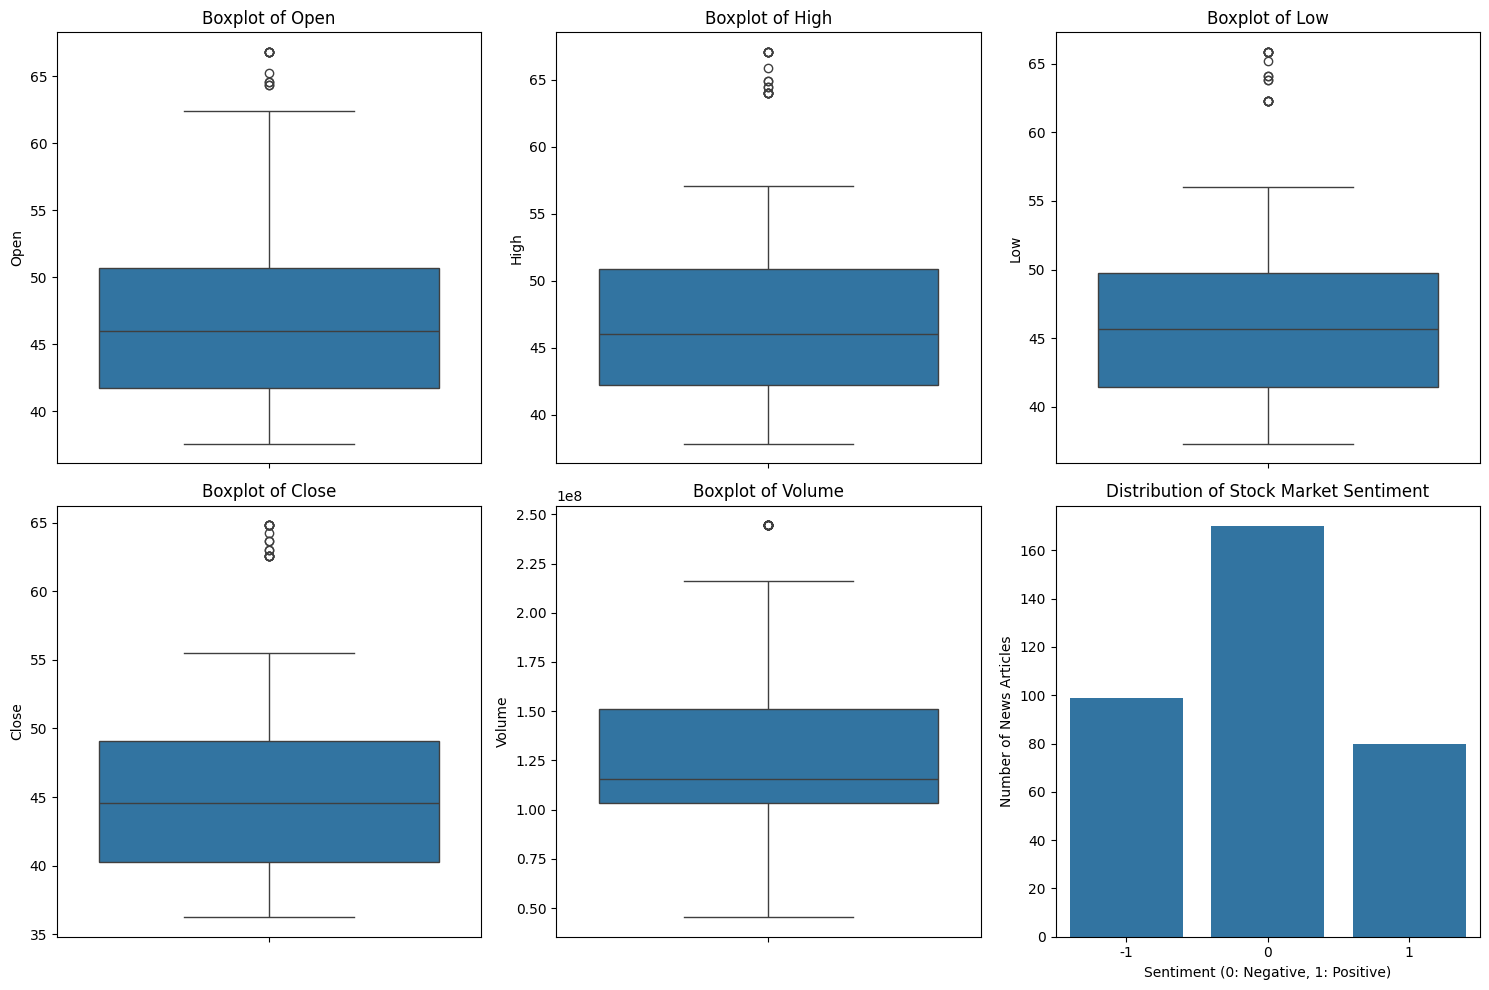

In [ ]:
plt.figure(figsize=(8, 6))

# Boxplot of numerical features
numerical_features = ['Open', 'High', 'Low', 'Close', 'Volume']
plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_features):
    plt.subplot(2, 3, i+1)
    sns.boxplot(y=col, data = df)
    plt.title(f'Boxplot of {col}')
plt.subplot(2,3,6)
sns.countplot(x='Label', data=df)
plt.title('Distribution of Stock Market Sentiment')
plt.xlabel('Sentiment (0: Negative, 1: Positive)')
plt.ylabel('Number of News Articles')

plt.tight_layout()
plt.show()

- We can see that pricing median values and outliers are relatively the same.
- The IQR is also around the same for all the values.
- Volume has only 1 outlier.
- We can now change our initial observation and say that 0 is the most common sentiment.

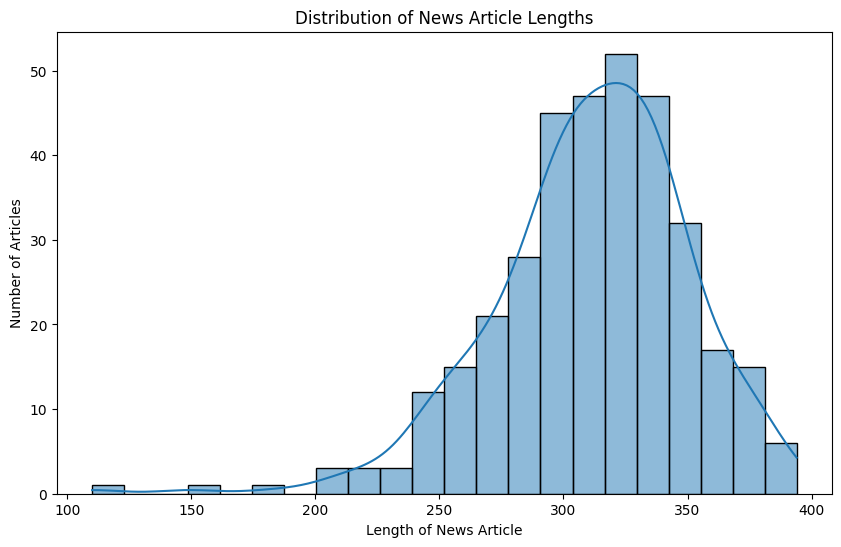

In [ ]:
# prompt: Compute and check the distribution of the length of news content

# Compute the length of each news article
data['News_Length'] = df['News'].apply(len)

# Create a distribution plot of the news article lengths
plt.figure(figsize=(10, 6))
sns.histplot(data['News_Length'], kde=True)
plt.title('Distribution of News Article Lengths')
plt.xlabel('Length of News Article')
plt.ylabel('Number of Articles')
plt.show()

- From this we can see that most articles are of 325 word lenght.

### Bivariate Analysis

* Correlation
* Sentiment Polarity vs Price
* Date vs Price

**Note**: The above points are listed to provide guidance on how to approach bivariate analysis. Analysis has to be done beyond the above listed points to get maximum scores.

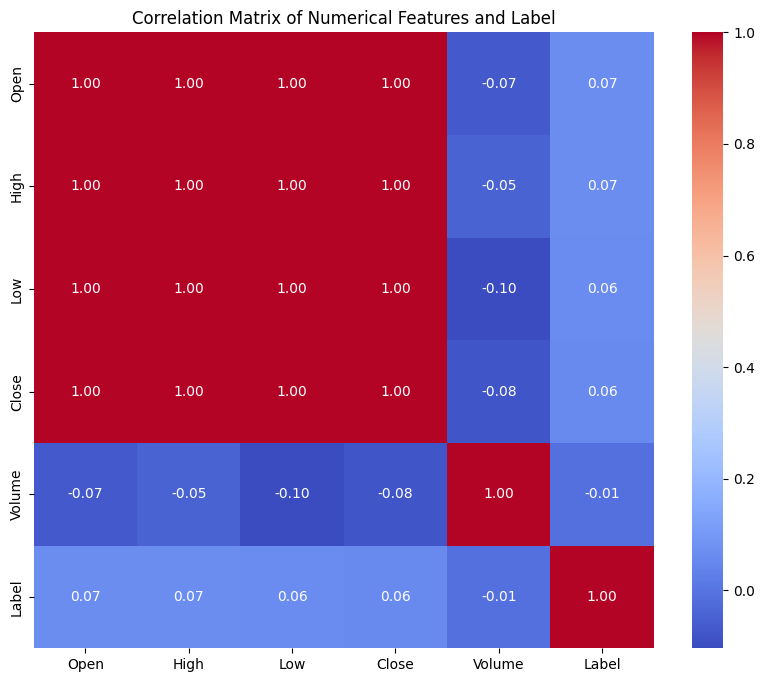

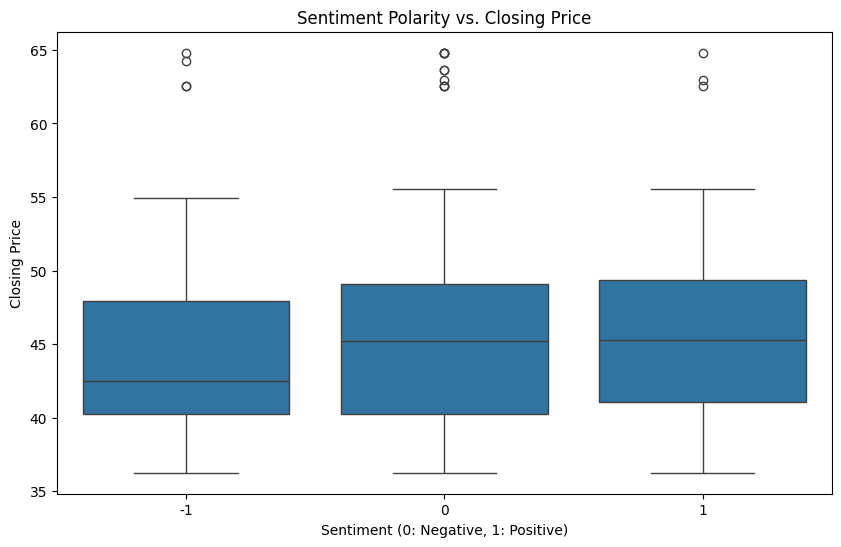

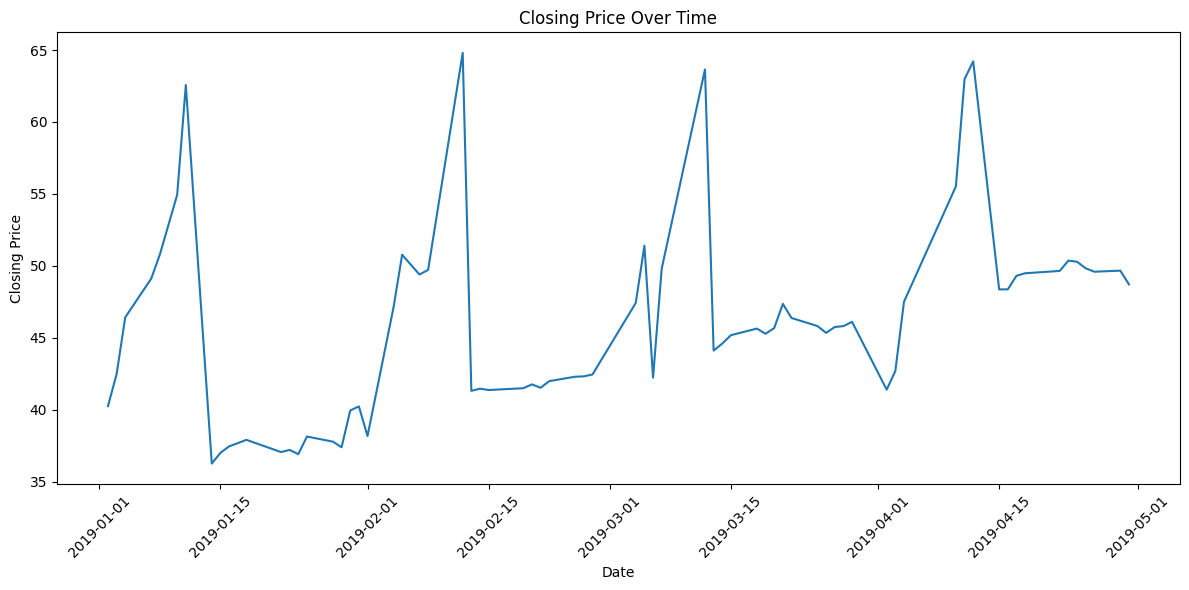

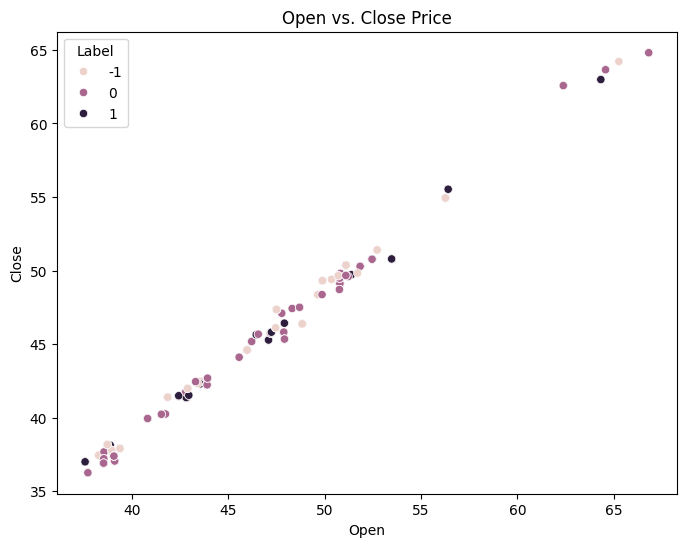

In [ ]:
# prompt: perform Birvariate analysis on the data including Correlation
# Sentiment Polarity vs Price
# Date vs Price

# Correlation Matrix
correlation_matrix = df[['Open', 'High', 'Low', 'Close', 'Volume', 'Label']].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Numerical Features and Label')
plt.show()

# Sentiment Polarity vs Price
# Assuming 'Label' represents sentiment (0: Negative, 1: Positive)
plt.figure(figsize=(10, 6))
sns.boxplot(x='Label', y='Close', data=df)
plt.title('Sentiment Polarity vs. Closing Price')
plt.xlabel('Sentiment (0: Negative, 1: Positive)')
plt.ylabel('Closing Price')
plt.show()

# Date vs Price (requires converting 'Date' to datetime if it's not already)
df['Date'] = pd.to_datetime(df['Date'])
plt.figure(figsize=(12, 6))
plt.plot(df['Date'], df['Close'])
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.title('Closing Price Over Time')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Further Bivariate Analysis (Examples)
# You can explore other relationships:
# - Scatter plots between different numerical features
# - Box plots of numerical features grouped by 'Label'
# - Line plots of 'Volume' over time
# - Analyze the relationship between 'Open' and 'Close' prices
# - Investigate the distribution of 'Volume' for positive and negative sentiment

# Example: Scatter plot of Open vs Close
plt.figure(figsize=(8, 6))
sns.scatterplot(x='Open', y='Close', data=df, hue='Label')
plt.title('Open vs. Close Price')
plt.show()

- With this we can see that negative news has a greater impact on close price than open price.

## **Data Preprocessing**

In [ ]:
dataset = data.copy()

### Preprocessing the Textual Column

In [ ]:
# Loading the Porter Stemmer
ps = PorterStemmer()

In [ ]:
def preprocess_text(text):
    # Convert to lowercase
    text = text.lower()

    # Remove special characters and numbers
    text = re.sub(r'[^A-Za-z\s]', '', text)

    # Remove extra whitespaces
    text = re.sub(r'\s+', ' ', text).strip()

    # Split text into separate words
    words = text.split()

    # Removing English language stopwords
    text = ' '.join([word for word in words if word not in stopwords.words('english')])

    # Applying the Porter Stemmer on every word of a message and joining the stemmed words back into a single string
    text = ' '.join([ps.stem(word) for word in words])

    return text

In [ ]:
# preprocessing the textual column
dataset['News_text_clean'] = dataset['News'].apply(preprocess_text)

## **Word Embeddings**

### Word2Vec

In [ ]:
# Creating a list of all words in our data
words_list = [item.split(" ") for item in dataset['News_text_clean'].values]

In [ ]:
# Creating an instance of Word2Vec
vec_size = 300
model_W2V = Word2Vec(words_list, vector_size = vec_size, min_count = 1, window=5, workers = 6)

In [ ]:
# Checking the size of the vocabulary
print("Length of the vocabulary is", len(list(model_W2V.wv.key_to_index)))

Length of the vocabulary is 2595


In [ ]:
# Checking the word embedding of a random word
word ="good"
model_W2V.wv[word]

array([-5.06276684e-03,  9.62909311e-03, -1.12746132e-03,  4.29942412e-03,
        5.81876782e-04, -2.22292226e-02,  1.45719526e-02,  4.18389216e-02,
        4.40584123e-03, -3.17598088e-03,  3.66252218e-03, -1.50510771e-02,
        2.78758723e-03, -2.75981287e-03, -9.03830398e-03, -1.62177254e-02,
        3.22022103e-03, -4.34324518e-03,  9.71522834e-03, -1.09549183e-02,
       -7.18285004e-03, -1.67882186e-03,  1.32064288e-02, -1.47322810e-03,
        8.26438610e-03,  3.06689093e-04, -1.59276482e-02,  2.61383620e-03,
       -9.33754724e-03, -1.49447983e-02,  6.06827904e-04, -6.35427097e-03,
        3.26380017e-03, -2.35180603e-03, -6.27124263e-03,  7.90229999e-03,
        6.83807395e-03, -1.58803649e-02,  4.03077080e-04,  1.73454254e-03,
       -7.85063766e-03,  3.17574572e-03,  5.73355192e-03, -8.93942360e-03,
        8.20030086e-03,  1.66477356e-02,  7.70303048e-03,  8.83171987e-03,
       -5.07899979e-03,  1.31078064e-02,  2.87828920e-03,  4.82300326e-04,
       -9.53530055e-03,  

In [ ]:
# Checking the word embedding of a random word
word = "fall"
model_W2V.wv[word]

array([-6.59762695e-03,  3.20398025e-02,  1.48240931e-03,  8.99149664e-03,
       -8.65191221e-04, -5.49511127e-02,  3.22410986e-02,  1.11375749e-01,
        1.12793762e-02, -9.74128116e-03,  3.59995454e-03, -3.50149460e-02,
        7.21157575e-03, -1.99679993e-02, -3.29674818e-02, -5.23875430e-02,
        1.61779970e-02, -5.46821998e-03,  2.93282140e-02, -2.47564819e-02,
       -1.49304327e-02, -1.15953432e-03,  2.88659800e-02, -1.50986982e-03,
        2.40348112e-02,  4.16933233e-03, -5.13726622e-02,  1.25504388e-02,
       -2.64964476e-02, -4.27825078e-02,  2.82673980e-03, -1.45511804e-02,
        9.78340209e-03, -1.39774550e-02, -9.10651032e-03,  2.14415267e-02,
        2.48415526e-02, -5.43598384e-02, -7.24873506e-03,  5.77582745e-03,
       -3.01256757e-02,  8.11314397e-03,  1.10689038e-02, -3.03190909e-02,
        1.77996531e-02,  3.76841314e-02,  2.08640117e-02,  1.68849528e-02,
       -1.68155078e-02,  3.17913331e-02,  9.92122199e-03,  6.73733046e-03,
       -3.21772173e-02, -

In [ ]:
# Checking the word embedding of a random word
word = "market"
model_W2V.wv[word]

array([-0.02433985,  0.10478355,  0.01123878,  0.02097341,  0.00326986,
       -0.18441063,  0.11510501,  0.39358926,  0.05153536, -0.03206167,
        0.02088122, -0.11715437,  0.0209792 , -0.05754327, -0.11334051,
       -0.17209387,  0.05011659, -0.02887646,  0.09573875, -0.0794054 ,
       -0.04108818, -0.00679927,  0.1069331 ,  0.00525768,  0.08607192,
        0.02421433, -0.18151781,  0.03792755, -0.08445793, -0.15156676,
        0.00535288, -0.04878189,  0.0229065 , -0.03501381, -0.02906692,
        0.08077446,  0.07863934, -0.17747273, -0.01491943,  0.02516267,
       -0.09621379,  0.02844579,  0.0409945 , -0.11165584,  0.05851961,
        0.1295962 ,  0.07781705,  0.05976474, -0.04512046,  0.12245678,
        0.03252782,  0.01472871, -0.10275763, -0.00262953, -0.01232379,
        0.17636344,  0.08664972,  0.04538473,  0.09954351,  0.00159655,
       -0.08710624, -0.01417914, -0.00160488,  0.02114104, -0.02224136,
        0.11657797, -0.03249538,  0.03392347, -0.12349024, -0.06

In [ ]:
# Retrieving the words present in the Word2Vec model's vocabulary
words = list(model_W2V.wv.key_to_index.keys())

# Retrieving word vectors for all the words present in the model's vocabulary
wvs = model_W2V.wv[words].tolist()

# Creating a dictionary of words and their corresponding vectors
word_vector_dict = dict(zip(words, wvs))

In [ ]:
def average_vectorizer_Word2Vec(doc):
    # Initializing a feature vector for the sentence
    feature_vector = np.zeros((vec_size,), dtype="float64")

    # Creating a list of words in the sentence that are present in the model vocabulary
    words_in_vocab = [word for word in doc.split() if word in words]

    # adding the vector representations of the words
    for word in words_in_vocab:
        feature_vector += np.array(word_vector_dict[word])

    # Dividing by the number of words to get the average vector
    if len(words_in_vocab) != 0:
        feature_vector /= len(words_in_vocab)

    return feature_vector

In [ ]:
# creating a dataframe of the vectorized documents
df_Word2Vec = pd.DataFrame(dataset['News_text_clean'].apply(average_vectorizer_Word2Vec).tolist(), columns=['Feature '+str(i) for i in range(vec_size)])
df_Word2Vec

,Feature 0,Feature 1,Feature 2,Feature 3,Feature 4,Feature 5,Feature 6,Feature 7,Feature 8,Feature 9,...,Feature 290,Feature 291,Feature 292,Feature 293,Feature 294,Feature 295,Feature 296,Feature 297,Feature 298,Feature 299
0,-0.021362,0.106312,0.013608,0.022941,0.003566,-0.187498,0.115098,0.399363,0.048823,-0.034416,...,0.054499,0.162172,0.154223,-0.005783,0.207901,0.190641,0.029036,-0.100375,0.144732,-0.030107
1,-0.021616,0.108435,0.013059,0.023186,0.003347,-0.190390,0.116969,0.406136,0.049577,-0.035038,...,0.055319,0.165424,0.157204,-0.005809,0.211351,0.194509,0.029625,-0.101801,0.147715,-0.030886
2,-0.019171,0.096194,0.011580,0.020554,0.003453,-0.169046,0.104148,0.361076,0.044515,-0.031344,...,0.049392,0.146930,0.139691,-0.004949,0.188253,0.172679,0.026238,-0.090289,0.130983,-0.027266
3,-0.020558,0.105297,0.012232,0.022578,0.003742,-0.184548,0.113149,0.392771,0.048658,-0.033733,...,0.053885,0.160186,0.152451,-0.005347,0.205080,0.188276,0.028021,-0.098522,0.142614,-0.030342
4,-0.021036,0.105414,0.012647,0.022144,0.003730,-0.185502,0.114159,0.396037,0.048867,-0.034012,...,0.053933,0.160945,0.153287,-0.005362,0.206530,0.189317,0.028808,-0.098879,0.143829,-0.030041
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
344,-0.014363,0.073581,0.009181,0.015752,0.002622,-0.128839,0.079370,0.273741,0.034410,-0.023418,...,0.037418,0.111780,0.105983,-0.003946,0.143562,0.131256,0.019970,-0.069297,0.099510,-0.021282
345,-0.014826,0.072851,0.009166,0.015997,0.002868,-0.126816,0.078028,0.271757,0.033300,-0.023363,...,0.037120,0.110542,0.105855,-0.004101,0.142249,0.129080,0.020196,-0.068599,0.098811,-0.020276
346,-0.016591,0.084446,0.009633,0.018450,0.002963,-0.147566,0.091240,0.314503,0.038845,-0.026792,...,0.042818,0.128181,0.121458,-0.004449,0.163968,0.150272,0.022774,-0.078468,0.113517,-0.024300
347,-0.019594,0.097307,0.011720,0.021488,0.003503,-0.171423,0.104884,0.364968,0.045106,-0.031358,...,0.050116,0.148613,0.140984,-0.005276,0.190342,0.174907,0.026491,-0.091600,0.132675,-0.027820


### GloVe

In [ ]:
glove_input_file = '/content/drive/MyDrive/Great Learning/Project 6: NLP/glove.6B.100d.txt.word2vec'
word2vec_output_file = 'glove.6B.100d.txt.word2vec'
glove_model = KeyedVectors.load_word2vec_format(glove_input_file, binary=False)

In [ ]:
# Checking the size of the vocabulary
print("Length of the vocabulary is", len(glove_model.index_to_key))

Length of the vocabulary is 400000


In [ ]:
# Checking the word embedding of a random word
word = "good"
glove_model[word]

array([-0.030769 ,  0.11993  ,  0.53909  , -0.43696  , -0.73937  ,
       -0.15345  ,  0.081126 , -0.38559  , -0.68797  , -0.41632  ,
       -0.13183  , -0.24922  ,  0.441    ,  0.085919 ,  0.20871  ,
       -0.063582 ,  0.062228 , -0.051234 , -0.13398  ,  1.1418   ,
        0.036526 ,  0.49029  , -0.24567  , -0.412    ,  0.12349  ,
        0.41336  , -0.48397  , -0.54243  , -0.27787  , -0.26015  ,
       -0.38485  ,  0.78656  ,  0.1023   , -0.20712  ,  0.40751  ,
        0.32026  , -0.51052  ,  0.48362  , -0.0099498, -0.38685  ,
        0.034975 , -0.167    ,  0.4237   , -0.54164  , -0.30323  ,
       -0.36983  ,  0.082836 , -0.52538  , -0.064531 , -1.398    ,
       -0.14873  , -0.35327  , -0.1118   ,  1.0912   ,  0.095864 ,
       -2.8129   ,  0.45238  ,  0.46213  ,  1.6012   , -0.20837  ,
       -0.27377  ,  0.71197  , -1.0754   , -0.046974 ,  0.67479  ,
       -0.065839 ,  0.75824  ,  0.39405  ,  0.15507  , -0.64719  ,
        0.32796  , -0.031748 ,  0.52899  , -0.43886  ,  0.6740

In [ ]:
# Checking the word embedding of a random word
word = "fall"
glove_model[word]

array([ 0.3264  ,  0.55822 ,  0.25533 , -0.10814 ,  0.04654 , -0.46577 ,
       -0.13963 ,  0.15362 , -0.23483 , -0.42804 ,  0.037924,  0.22895 ,
        0.18672 ,  0.23734 ,  0.34996 ,  0.037288, -0.46827 ,  0.15487 ,
       -0.16487 ,  0.11753 ,  0.30809 , -0.25441 ,  0.30979 ,  0.8051  ,
       -0.09219 , -0.062635, -0.38575 , -0.54978 ,  0.3019  , -0.54258 ,
        0.19739 , -0.29    ,  0.092703, -0.48055 , -0.48191 ,  0.72779 ,
        0.22876 , -0.45603 ,  0.037786, -0.32571 , -0.42623 , -0.058946,
       -0.52196 ,  0.18801 ,  0.14141 , -0.20073 ,  0.27084 , -0.026134,
        0.13288 , -1.4764  , -0.056972, -0.32662 ,  0.30494 ,  0.76331 ,
        0.16788 , -2.356   , -0.37616 , -0.011489,  1.9827  ,  0.36153 ,
       -0.22095 ,  1.0825  , -0.67676 ,  0.096369,  0.48564 ,  0.20256 ,
        0.16667 , -0.35918 ,  0.13848 ,  0.096536,  0.13312 , -0.069298,
       -0.69095 ,  0.35564 , -0.50851 , -0.3494  , -0.33562 ,  0.45363 ,
       -0.28949 ,  0.032191,  0.17248 ,  0.1475  , 

In [ ]:
# Checking the word embedding of a random word
word = "market"
glove_model[word]

array([ 0.39093  ,  0.23755  ,  0.44855  ,  0.11237  , -0.25996  ,
       -1.2248   , -0.44237  , -0.53491  ,  0.37142  , -0.61981  ,
       -0.27387  , -0.032213 ,  0.082629 , -0.52986  ,  0.13012  ,
        0.21703  , -0.45026  , -0.0048895,  0.34887  , -0.26069  ,
        0.56598  , -0.36219  ,  0.41926  ,  0.23441  , -0.29407  ,
       -0.27044  ,  0.29339  , -0.73905  , -0.75965  ,  0.64661  ,
       -0.038757 ,  0.38495  , -0.32314  ,  0.040322 ,  0.24036  ,
        0.35167  ,  0.47404  ,  0.014959 ,  0.12105  , -1.0398   ,
        0.27639  , -1.3785   , -0.22851  , -0.098074 ,  0.1495   ,
       -0.2815   ,  0.31682  , -0.10208  , -0.08586  , -1.5114   ,
       -0.48255  ,  0.15131  ,  0.0080133,  0.74594  , -0.20163  ,
       -2.5268   , -0.82083  ,  0.1143   ,  2.4665   ,  0.19841  ,
        0.1146   ,  0.10083  , -0.60936  ,  0.76722  ,  0.025978 ,
       -0.036936 ,  0.46744  , -0.77073  ,  0.83992  , -0.032931 ,
       -0.13127  , -0.097367 , -0.42634  , -0.49478  , -0.4079

In [ ]:
# Retrieving the words present in the GloVe model's vocabulary
glove_words = glove_model.index_to_key

# Creating a dictionary of words and their corresponding vectors
glove_word_vector_dict = dict(zip(glove_model.index_to_key,list(glove_model.vectors)))


In [ ]:
vec_size=100

In [ ]:
def average_vectorizer_GloVe(doc):
    # Initializing a feature vector for the sentence
    feature_vector = np.zeros((vec_size,), dtype="float64")

    # Creating a list of words in the sentence that are present in the model vocabulary
    words_in_vocab = [word for word in doc.split() if word in glove_words]

    # adding the vector representations of the words
    for word in words_in_vocab:
        feature_vector += np.array(glove_word_vector_dict[word])

    # Dividing by the number of words to get the average vector
    if len(words_in_vocab) != 0:
        feature_vector /= len(words_in_vocab)

    return feature_vector

In [ ]:
# creating a dataframe of the vectorized documents
df_Glove = pd.DataFrame(dataset['News_text_clean'].apply(average_vectorizer_GloVe).tolist(), columns=['Feature '+str(i) for i in range(vec_size)])
df_Glove

,Feature 0,Feature 1,Feature 2,Feature 3,Feature 4,Feature 5,Feature 6,Feature 7,Feature 8,Feature 9,...,Feature 90,Feature 91,Feature 92,Feature 93,Feature 94,Feature 95,Feature 96,Feature 97,Feature 98,Feature 99
0,-0.025091,0.042967,0.116176,-0.099245,-0.099562,-0.266941,-0.129265,0.080286,-0.090646,0.008517,...,-0.017063,0.156885,-0.173618,0.017792,-0.351731,0.080720,-0.009300,-0.071766,0.400022,0.046329
1,0.075789,0.279267,0.286092,-0.077898,-0.022339,-0.379945,-0.178142,-0.061498,-0.161026,0.088777,...,-0.016551,0.146223,-0.238209,-0.091082,-0.463150,0.093832,0.016530,-0.174671,0.531049,-0.026343
2,0.014897,0.207172,0.331676,-0.114473,0.116600,-0.374662,-0.168155,-0.010315,-0.086171,0.033631,...,0.120662,0.082600,-0.143998,-0.157486,-0.532710,0.129624,-0.030218,-0.157017,0.557803,-0.121953
3,-0.090954,0.123357,0.444133,-0.051370,0.011666,-0.228597,-0.246173,0.033390,-0.150130,0.002191,...,0.082228,0.127173,-0.272930,0.134984,-0.438773,0.074060,-0.046727,-0.261468,0.554238,0.067364
4,-0.016286,0.095670,0.158662,0.009404,0.022072,-0.162877,-0.133161,-0.037780,-0.213474,0.109459,...,0.076108,0.076419,-0.141350,-0.127092,-0.298950,0.181038,0.048829,-0.186550,0.361910,-0.034064
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
344,-0.089744,0.078603,0.355204,-0.269606,0.093859,0.229220,-0.084779,0.248824,-0.119752,0.015531,...,0.113815,-0.164158,0.054945,0.112785,-0.391273,0.064565,-0.150172,-0.331076,0.552668,0.277021
345,0.153751,0.155163,0.296305,0.042006,0.105729,-0.252609,-0.260229,-0.007662,-0.240935,-0.035625,...,0.056417,0.102090,-0.138025,0.059017,-0.511696,0.348926,0.062021,-0.030892,0.483785,0.106074
346,0.033072,0.072522,0.241457,-0.146820,-0.050864,-0.095216,-0.124294,0.112551,-0.242520,-0.060998,...,-0.011031,0.144369,-0.168728,0.120561,-0.412585,-0.009892,-0.123141,-0.258367,0.350678,0.055361
347,-0.113620,0.056063,0.216818,-0.095542,0.004862,-0.195284,-0.223138,0.078362,-0.195751,-0.034510,...,0.025093,0.007117,-0.140764,-0.045426,-0.433007,0.026847,0.035699,-0.281933,0.497955,0.019963


### Sentence Transformer

In [ ]:
model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.7k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

1_Pooling/config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

#### Encoding the Data Set

In [ ]:
# setting the device to GPU if available, else CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
# encoding the dataset
embedding_matrix = model.encode(data['News'], show_progress_bar=True, device=device)

Batches:   0%|          | 0/11 [00:00<?, ?it/s]

In [ ]:
# printing the shape of the embedding matrix
embedding_matrix.shape

(349, 384)

- Each news article has been converted to a 384-dimensional vector

In [ ]:
# printing the embedding vector of the first review in the dataset
embedding_matrix[0]

array([-2.02309177e-03, -3.67734618e-02,  7.73542747e-02,  4.67134453e-02,
        3.25521417e-02,  2.10233801e-03,  4.32835072e-02,  3.95345204e-02,
        5.82280159e-02,  8.87509063e-03,  7.09636658e-02,  4.99076769e-02,
        6.46608025e-02, -4.97968402e-03, -1.30518908e-02, -2.98355650e-02,
       -8.91323574e-03, -7.82000944e-02, -2.17109080e-02, -5.24822213e-02,
       -5.14276288e-02, -3.30719948e-02, -3.32051441e-02,  4.18125466e-02,
        7.99547806e-02,  1.54092424e-02, -2.15781108e-02,  5.19438200e-02,
       -4.65799235e-02, -3.71372327e-02, -1.04225501e-01,  9.86079052e-02,
        5.21786362e-02,  3.46578658e-02,  1.48810344e-02, -4.47350834e-03,
        5.70118129e-02, -2.41722800e-02,  2.14049425e-02, -6.52145073e-02,
       -3.30645256e-02,  1.61961466e-02, -6.63142055e-02,  4.39943708e-02,
        3.82152535e-02, -4.86519262e-02,  1.62651259e-02, -4.02665511e-02,
       -3.34573910e-03,  3.20956036e-02, -3.91194131e-03, -1.26830200e-02,
        4.49699126e-02,  

- We have not trained or fine-tuned the model. We have used the pre-trained model to encode the dataset.

## **Sentiment Analysis**

### Model Building

In [ ]:
# creating a function to plot the confusion matrix
def plot_confusion_matrix(actual, predicted):
    cm = confusion_matrix(actual, predicted)

    plt.figure(figsize = (5, 4))
    label_list = encoder.classes_.tolist()
    sns.heatmap(cm, annot = True,  fmt = '.0f',cmap='Blues', xticklabels = label_list, yticklabels = label_list)
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

In [ ]:
# defining a function to compute different metrics to check performance of a classification model built using sklearn
def model_performance_classification_sklearn(model, predictors, target):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    acc = accuracy_score(target, pred)  # to compute Accuracy
    recall = recall_score(target, pred, average='weighted')  # to compute Recall
    precision = precision_score(target, pred, average='weighted')  # to compute Precision
    f1 = f1_score(target, pred, average='weighted')  # to compute F1-score

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {
            "Accuracy": acc,
            "Recall": recall,
            "Precision": precision,
            "F1": f1,
        },
        index=[0],
    )

    return df_perf

#### Random Forest with Word2Vec

In [ ]:
# Storing independent variable
X = df_Word2Vec.copy()

# Storing target variable
y = dataset['Label']

In [ ]:
# Split data into training and testing set.
X_train, X_test, y_train, y_test = train_test_split(X ,y, test_size = 0.25, random_state = 42)

In [ ]:
# Label Encoding
encoder = LabelEncoder()

# fitting the encoder to the training labels
y_train_enc = encoder.fit_transform(y_train)

# applying the encoder mapping from training labels to test labels
y_test_enc = encoder.transform(y_test)

RF Base Model

In [ ]:
# Building the model
rf_word2vec_base = RandomForestClassifier(class_weight= "balanced",random_state = 42)

# Fitting on train data
rf_word2vec_base.fit(X_train, y_train_enc)

RandomForestClassifier(class_weight='balanced', random_state=42)

In [ ]:
# Predicting on train data
y_pred_train_base = rf_word2vec_base.predict(X_train)

# Predicting on test data
y_pred_test_base = rf_word2vec_base.predict(X_test)

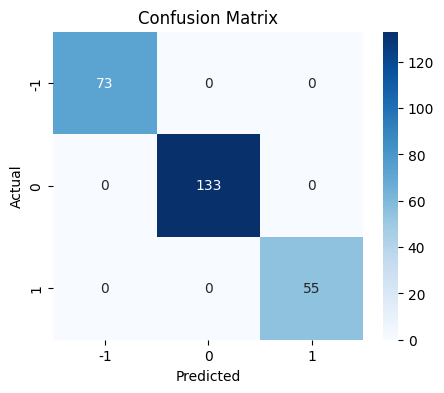

In [ ]:
plot_confusion_matrix(y_train_enc, y_pred_train_base)

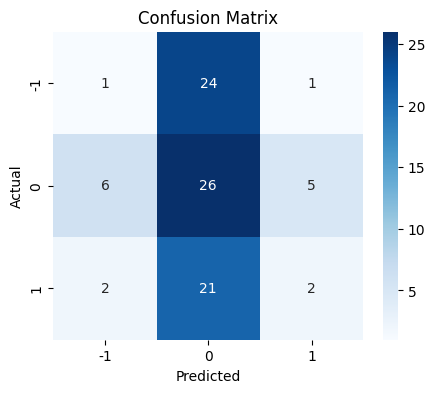

In [ ]:
plot_confusion_matrix(y_test_enc, y_pred_test_base)

In [ ]:
#Calculating different metrics on training data
word2vec_base_train=model_performance_classification_sklearn(rf_word2vec_base, X_train,y_train_enc)
print("Training performance:\n", word2vec_base_train)

Training performance:
    Accuracy  Recall  Precision   F1
0       1.0     1.0        1.0  1.0


In [ ]:
#Calculating different metrics on training data
word2vec_base_test=model_performance_classification_sklearn(rf_word2vec_base, X_test,y_test_enc)
print("Testing performance:\n", word2vec_base_test)

Testing performance:
    Accuracy    Recall  Precision        F1
0  0.329545  0.329545    0.25782  0.253759


RF Model with Grid Search

In [ ]:
# Choose the type of classifier.
word2vec_rf_tuned = RandomForestClassifier(class_weight= "balanced",random_state=1,bootstrap=True)

parameters = {
    'max_depth': list(np.arange(3,10,3)),
    'n_estimators': np.arange(30,90,25),
    'max_features': [0.3,0.4,.1]
}

# Run the grid search
grid_obj = GridSearchCV(word2vec_rf_tuned, parameters, scoring='recall',cv=3,n_jobs=-1)
grid_obj = grid_obj.fit(X_train, y_train_enc)

# Set the clf to the best combination of parameters
word2vec_rf_tuned = grid_obj.best_estimator_

# Fit the best algorithm to the data.
word2vec_rf_tuned.fit(X_train, y_train_enc)

RandomForestClassifier(class_weight='balanced', max_depth=3, max_features=0.3,
                       n_estimators=30, random_state=1)

In [ ]:
# Predicting on train data
y_pred_train_tuned = word2vec_rf_tuned.predict(X_train)

# Predicting on test data
y_pred_test_tuned = word2vec_rf_tuned.predict(X_test)

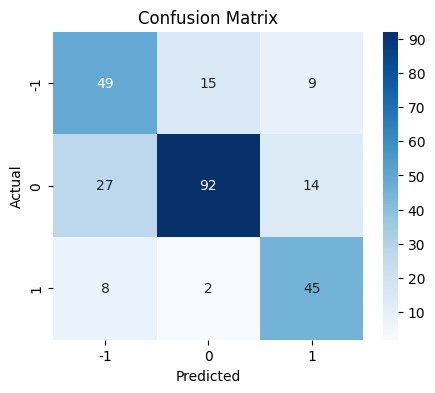

In [ ]:
plot_confusion_matrix(y_train_enc, y_pred_train_tuned)

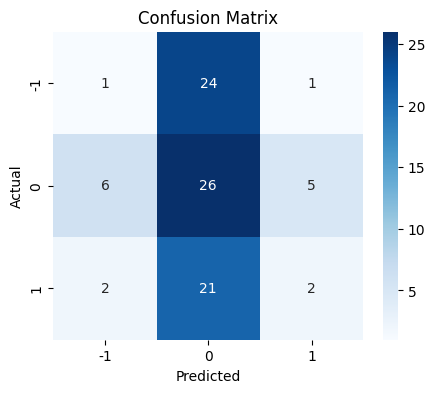

In [ ]:
plot_confusion_matrix(y_test_enc, y_pred_test_base)

In [ ]:
#Calculating different metrics on training data
word2vec_tuned_train=model_performance_classification_sklearn(word2vec_rf_tuned, X_train,y_train_enc)
print("Training performance:\n", word2vec_tuned_train)

Training performance:
    Accuracy    Recall  Precision        F1
0  0.712644  0.712644    0.73271  0.716225


In [ ]:
#Calculating different metrics on training data
word2vec_tuned_test=model_performance_classification_sklearn(word2vec_rf_tuned, X_test,y_test_enc)
print("Testing performance:\n", word2vec_tuned_test)

Testing performance:
    Accuracy    Recall  Precision        F1
0  0.397727  0.397727   0.399452  0.397206


#### Random Forest with Glove

In [ ]:
# Storing independent variable
X = df_Glove.copy()

# Storing target variable
y = dataset['Label']

In [ ]:
# Split data into training and testing set.
X_train_glove, X_test_glove, y_train_glove, y_test_glove = train_test_split(X ,y, test_size = 0.25, random_state = 42)

In [ ]:
# Label Encoding
encoder = LabelEncoder()

# fitting the encoder to the training labels
y_train_enc_glove = encoder.fit_transform(y_train_glove)

# applying the encoder mapping from training labels to test labels
y_test_enc_glove = encoder.transform(y_test_glove)

RF Base Model

In [ ]:
# Building the model
rf_glovec_base = RandomForestClassifier(class_weight= "balanced",random_state = 42)

# Fitting on train data
rf_glovec_base.fit(X_train_glove, y_train_enc_glove)

RandomForestClassifier(class_weight='balanced', random_state=42)

In [ ]:
# Predicting on train data
y_pred_train_base_gl = rf_glovec_base.predict(X_train_glove)

# Predicting on test data
y_pred_test_base_gl = rf_glovec_base.predict(X_test_glove)

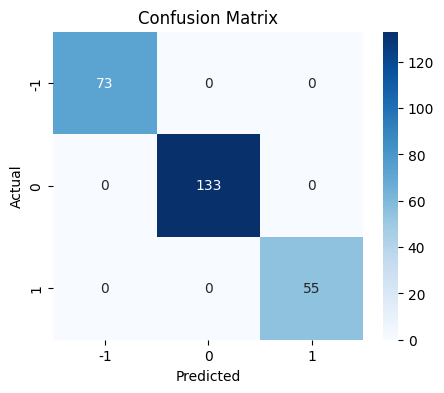

In [ ]:
plot_confusion_matrix(y_train_enc_glove, y_pred_train_base_gl)

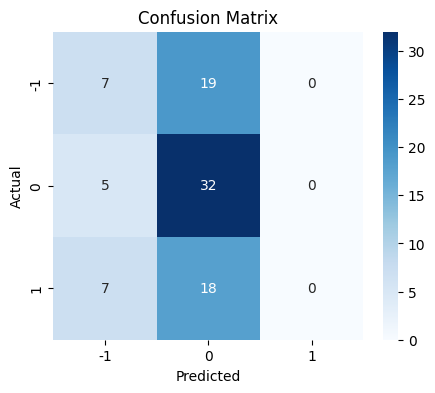

In [ ]:
plot_confusion_matrix(y_test_enc_glove, y_pred_test_base_gl)

In [ ]:
#Calculating different metrics on training data
glove_base_train=model_performance_classification_sklearn(rf_glovec_base, X_train_glove,y_train_enc_glove)
print("Training performance:\n", glove_base_train)

Training performance:
    Accuracy  Recall  Precision   F1
0       1.0     1.0        1.0  1.0


In [ ]:
#Calculating different metrics on training data
glove_base_test=model_performance_classification_sklearn(rf_glovec_base, X_test_glove,y_test_enc_glove)
print("Testing performance:\n", glove_base_test)

Testing performance:
    Accuracy    Recall  Precision        F1
0  0.443182  0.443182   0.303845  0.345779


RF Model with Grid Search

In [ ]:
# Choose the type of classifier.
glove_rf_tuned = RandomForestClassifier(class_weight= "balanced",random_state=1,bootstrap=True)

parameters = {
    'max_depth': list(np.arange(3,10,2)),
    'n_estimators': np.arange(30,90,25),
    'max_features': [0.3,0.4,.1]
}

# Run the grid search
grid_obj = GridSearchCV(glove_rf_tuned, parameters, scoring='recall',cv=5,n_jobs=-1)
grid_obj = grid_obj.fit(X_train_glove, y_train_enc_glove)

# Set the clf to the best combination of parameters
glove_rf_tuned = grid_obj.best_estimator_

# Fit the best algorithm to the data.
glove_rf_tuned.fit(X_train_glove, y_train_enc_glove)

RandomForestClassifier(class_weight='balanced', max_depth=3, max_features=0.3,
                       n_estimators=30, random_state=1)

In [ ]:
# Predicting on train data
y_pred_train_tuned_gl = glove_rf_tuned.predict(X_train_glove)

# Predicting on test data
y_pred_test_tuned_gl = glove_rf_tuned.predict(X_test_glove)

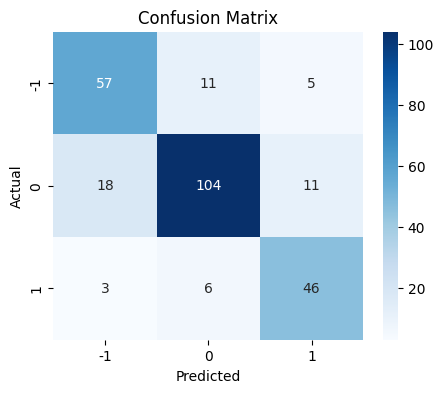

In [ ]:
plot_confusion_matrix(y_train_enc_glove, y_pred_train_tuned_gl)

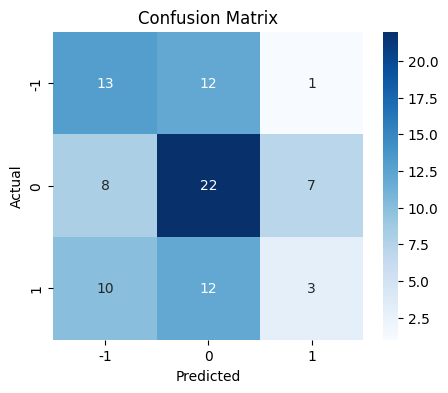

In [ ]:
plot_confusion_matrix(y_test_enc_glove, y_pred_test_tuned_gl)

In [ ]:
#Calculating different metrics on training data
glove_tuned_train=model_performance_classification_sklearn(glove_rf_tuned, X_train_glove,y_train_enc_glove)
print("Training performance:\n", glove_tuned_train)

Training performance:
    Accuracy    Recall  Precision        F1
0  0.793103  0.793103   0.798723  0.794153


In [ ]:
#Calculating different metrics on training data
glove_tuned_test=model_performance_classification_sklearn(glove_rf_tuned, X_test_glove,y_test_enc_glove)
print("Testing performance:\n", glove_tuned_test)

Testing performance:
    Accuracy    Recall  Precision        F1
0  0.431818  0.431818   0.402467  0.405009


### Sentence Transformer

In [ ]:
meanDistortions = []
clusters = range(2, 11)

for k in clusters:
    clusterer = KMeans(n_clusters=k, random_state=1)
    clusterer.fit(embedding_matrix)

    prediction = clusterer.predict(embedding_matrix)

    distortion = sum(
        np.min(cdist(embedding_matrix, clusterer.cluster_centers_, "euclidean"), axis=1) ** 2
    )
    meanDistortions.append(distortion)

    print("Number of Clusters:", k, "\tAverage Distortion:", distortion)

Number of Clusters: 2 	Average Distortion: 257.79868846449835
Number of Clusters: 3 	Average Distortion: 252.04993983708644
Number of Clusters: 4 	Average Distortion: 244.17818789202965
Number of Clusters: 5 	Average Distortion: 242.6605822298184
Number of Clusters: 6 	Average Distortion: 235.30652047858888
Number of Clusters: 7 	Average Distortion: 232.08861118705588
Number of Clusters: 8 	Average Distortion: 229.0452235732693
Number of Clusters: 9 	Average Distortion: 226.15465740192326
Number of Clusters: 10 	Average Distortion: 223.42286996518143


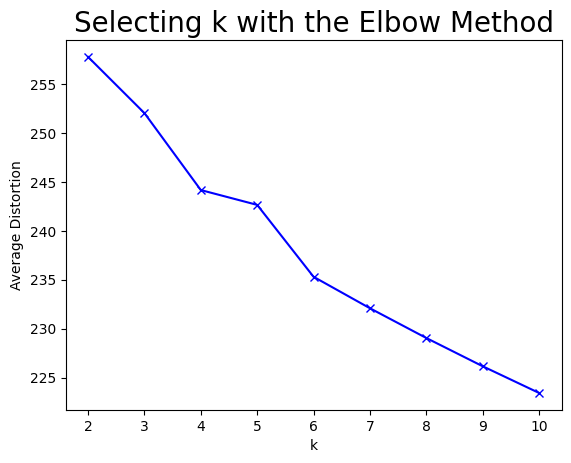

In [ ]:
plt.plot(clusters, meanDistortions, "bx-")
plt.xlabel("k")
plt.ylabel("Average Distortion")
plt.title("Selecting k with the Elbow Method", fontsize=20)
plt.show()

- Apropriate K value from the Elbow curve is 2

In [ ]:
sil_score = []
cluster_list = range(2, 10)

for n_clusters in cluster_list:
    clusterer = KMeans(n_clusters=n_clusters, random_state=1)

    preds = clusterer.fit_predict((embedding_matrix))

    score = silhouette_score(embedding_matrix, preds)
    sil_score.append(score)

    print("For n_clusters = {}, the silhouette score is {})".format(n_clusters, score))

For n_clusters = 2, the silhouette score is 0.06074509024620056)
For n_clusters = 3, the silhouette score is 0.05091124027967453)
For n_clusters = 4, the silhouette score is 0.04280789941549301)
For n_clusters = 5, the silhouette score is 0.0324106402695179)
For n_clusters = 6, the silhouette score is 0.038931939750909805)
For n_clusters = 7, the silhouette score is 0.04101463407278061)
For n_clusters = 8, the silhouette score is 0.041057609021663666)
For n_clusters = 9, the silhouette score is 0.03440581634640694)


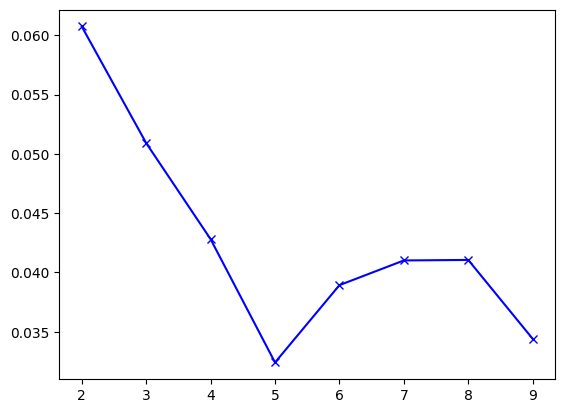

In [ ]:
plt.plot(cluster_list, sil_score, "bx-")
plt.show()

- The silhouette coefficient for 2 clusters is the highest.
- While models show that we should proceed with 2 clusters it is in the projects best interest to have 3 clusters, 1 for each sentiment level.

In [ ]:
# defining the number of clusters/categories
n_categories = 3

# fitting the model
kmeans = KMeans(n_clusters=n_categories, random_state=1).fit(embedding_matrix)

In [ ]:
# checking the cluster centers
centers = kmeans.cluster_centers_
centers

array([[-0.02049274, -0.00823878,  0.04153991, ..., -0.08699623,
         0.03591416,  0.04291194],
       [ 0.00304195, -0.01600422,  0.04685843, ..., -0.1066425 ,
        -0.02345447,  0.05932626],
       [-0.01890733, -0.00483673,  0.02671999, ..., -0.0478285 ,
         0.03620532,  0.01616417]], dtype=float32)

In [ ]:
# creating a copy of the data
clustered_data = data.copy()

# assigning the cluster/category labels
clustered_data['Label'] = kmeans.labels_

clustered_data.head()

,Date,News,Open,High,Low,Close,Volume,Label,News_Length
0,2019-01-02,"The tech sector experienced a significant decline in the aftermarket following Apple's Q1 revenue warning. Notable suppliers, including Skyworks, Broadcom, Lumentum, Qorvo, and TSMC, saw their stocks drop in response to Apple's downward revision of its revenue expectations for the quarter, previously announced in January.",41.740002,42.244999,41.482498,40.246914,130672400,1,324
1,2019-01-02,"Apple lowered its fiscal Q1 revenue guidance to $84 billion from earlier estimates of $89-$93 billion due to weaker than expected iPhone sales. The announcement caused a significant drop in Apple's stock price and negatively impacted related suppliers, leading to broader market declines for tech indices such as Nasdaq 10",41.740002,42.244999,41.482498,40.246914,130672400,0,323
2,2019-01-02,"Apple cut its fiscal first quarter revenue forecast from $89-$93 billion to $84 billion due to weaker demand in China and fewer iPhone upgrades. CEO Tim Cook also mentioned constrained sales of Airpods and Macbooks. Apple's shares fell 8.5% in post market trading, while Asian suppliers like Hon",41.740002,42.244999,41.482498,40.246914,130672400,1,296
3,2019-01-02,"This news article reports that yields on long-dated U.S. Treasury securities hit their lowest levels in nearly a year on January 2, 2019, due to concerns about the health of the global economy following weak economic data from China and Europe, as well as the partial U.S. government shutdown. Apple",41.740002,42.244999,41.482498,40.246914,130672400,1,300
4,2019-01-02,"Apple's revenue warning led to a decline in USD JPY pair and a gain in Japanese yen, as investors sought safety in the highly liquid currency. Apple's underperformance in Q1, with forecasted revenue of $84 billion compared to analyst expectations of $91.5 billion, triggered risk aversion mood in markets",41.740002,42.244999,41.482498,40.246914,130672400,1,305


Check random news articles from each label

In [ ]:
# for each cluster, printing the 5 random news articles
for i in range(3):
    print(i)
    # Check if 'Text' column exists, if not try other potential column names
    if 'News' in clustered_data.columns:
        print(clustered_data.loc[clustered_data.Label == i, 'News'].sample(3, random_state=1).values)
    elif 'News' in clustered_data.columns: # Check for lowercase 'text'
        print(clustered_data.loc[clustered_data.Label == i, 'News'].sample(3, random_state=1).values)
    # Add more elif conditions for other potential column names if necessary
    else:
        print("Column 'News' not found in the DataFrame. Please check the column names.")
    print("\n")

0
["Apple is under investigation by the Dutch competition agency, ACM, for allegedly favoring its own apps on the App Store. The probe may expand to Google's Play Store due to similar business practices. Indications of possible anti-competitive behavior include preferential treatment for Apple's own apps, mandatory use of its payment systems with"
 ' EU antitrust regulators should consider compelling tech giants like Google and Amazon to share their data with competitors, instead of breaking them up, according to a report from three academics appointed by European Commissioner Margrethe Vestager. The experts also recommended faster investigations and stronger arguments against "killer acquisitions" to prevent dominance'
 ' Apple reported spending over $60 billion with around 9,000 U.S. component suppliers and companies in 2018, marking a more than 10% increase from the previous year. Since 2011, Apple has generated or supported over 2 million jobs across all 50 states in']


1
['Europe

Based on the above news articles, we can see that they can be categorized as follows:

0: -1,
1: 1,
2: 0

In [ ]:
# dictionary of cluster label to category
category_dict = {
     0: -1,
     1: 1,
     2: 0,
}

# mapping cluster labels to categories
clustered_data['Label'] = clustered_data['Label'].map(category_dict)

clustered_data.head()

,Date,News,Open,High,Low,Close,Volume,Label,News_Length
0,2019-01-02,"The tech sector experienced a significant decline in the aftermarket following Apple's Q1 revenue warning. Notable suppliers, including Skyworks, Broadcom, Lumentum, Qorvo, and TSMC, saw their stocks drop in response to Apple's downward revision of its revenue expectations for the quarter, previously announced in January.",41.740002,42.244999,41.482498,40.246914,130672400,1,324
1,2019-01-02,"Apple lowered its fiscal Q1 revenue guidance to $84 billion from earlier estimates of $89-$93 billion due to weaker than expected iPhone sales. The announcement caused a significant drop in Apple's stock price and negatively impacted related suppliers, leading to broader market declines for tech indices such as Nasdaq 10",41.740002,42.244999,41.482498,40.246914,130672400,-1,323
2,2019-01-02,"Apple cut its fiscal first quarter revenue forecast from $89-$93 billion to $84 billion due to weaker demand in China and fewer iPhone upgrades. CEO Tim Cook also mentioned constrained sales of Airpods and Macbooks. Apple's shares fell 8.5% in post market trading, while Asian suppliers like Hon",41.740002,42.244999,41.482498,40.246914,130672400,1,296
3,2019-01-02,"This news article reports that yields on long-dated U.S. Treasury securities hit their lowest levels in nearly a year on January 2, 2019, due to concerns about the health of the global economy following weak economic data from China and Europe, as well as the partial U.S. government shutdown. Apple",41.740002,42.244999,41.482498,40.246914,130672400,1,300
4,2019-01-02,"Apple's revenue warning led to a decline in USD JPY pair and a gain in Japanese yen, as investors sought safety in the highly liquid currency. Apple's underperformance in Q1, with forecasted revenue of $84 billion compared to analyst expectations of $91.5 billion, triggered risk aversion mood in markets",41.740002,42.244999,41.482498,40.246914,130672400,1,305


Comparing with Actual Categories

In [ ]:
# adding the actual categories to our dataframe
clustered_data['Actual Category'] = df['Label'].values

In [ ]:
print(classification_report(clustered_data['Actual Category'], clustered_data['Label']))

              precision    recall  f1-score   support

          -1       0.23      0.30      0.26        99
           0       0.59      0.26      0.37       170
           1       0.22      0.39      0.28        80

    accuracy                           0.30       349
   macro avg       0.35      0.32      0.30       349
weighted avg       0.40      0.30      0.32       349



We had an accuracy of 30% without looking at the labels. This is a poor model lets analyze incorrect predictions.

**Analyzing Incorrect Predictions**

In [ ]:
# creating a dataframe of incorrect categorizations
incorrect_category_data = clustered_data[clustered_data['Actual Category'] != clustered_data['Label']].copy()
incorrect_category_data.shape

(243, 10)

In [ ]:
incorrect_category_data.head()

,Date,News,Open,High,Low,Close,Volume,Label,News_Length,Actual Category
0,2019-01-02,"The tech sector experienced a significant decline in the aftermarket following Apple's Q1 revenue warning. Notable suppliers, including Skyworks, Broadcom, Lumentum, Qorvo, and TSMC, saw their stocks drop in response to Apple's downward revision of its revenue expectations for the quarter, previously announced in January.",41.740002,42.244999,41.482498,40.246914,130672400,1,324,-1
2,2019-01-02,"Apple cut its fiscal first quarter revenue forecast from $89-$93 billion to $84 billion due to weaker demand in China and fewer iPhone upgrades. CEO Tim Cook also mentioned constrained sales of Airpods and Macbooks. Apple's shares fell 8.5% in post market trading, while Asian suppliers like Hon",41.740002,42.244999,41.482498,40.246914,130672400,1,296,-1
3,2019-01-02,"This news article reports that yields on long-dated U.S. Treasury securities hit their lowest levels in nearly a year on January 2, 2019, due to concerns about the health of the global economy following weak economic data from China and Europe, as well as the partial U.S. government shutdown. Apple",41.740002,42.244999,41.482498,40.246914,130672400,1,300,-1
4,2019-01-02,"Apple's revenue warning led to a decline in USD JPY pair and a gain in Japanese yen, as investors sought safety in the highly liquid currency. Apple's underperformance in Q1, with forecasted revenue of $84 billion compared to analyst expectations of $91.5 billion, triggered risk aversion mood in markets",41.740002,42.244999,41.482498,40.246914,130672400,1,305,-1
5,2019-01-02,"Apple CEO Tim Cook discussed the company's Q1 warning on CNBC, attributing US-China trade tensions as a factor. Despite not mentioning iPhone unit sales specifically, Cook indicated Apple may comment on them again. Services revenue is projected to exceed $10.8 billion in Q1. Cook also addressed the lack of",41.740002,42.244999,41.482498,40.246914,130672400,-1,307,0


In [ ]:
idx = 24

print('Distance from Actual Category')
print(cdist(embedding_matrix[idx].reshape(1,-1), kmeans.cluster_centers_[[2]], "euclidean")[0,0])

print('Distance from Predicted Category')
print(cdist(embedding_matrix[idx].reshape(1,-1), kmeans.cluster_centers_[[0]], "euclidean")[0,0])

Distance from Actual Category
0.9884036100011278
Distance from Predicted Category
0.9958741743086597


We see that the distance of the particular news article from the cluster centers of the actual and predicted categories is almost similar.

Based on this, we can say that a better approach of categorizing these news articles would be to assign more than one category to these news article.

- To conclude based on these models the GloVe model would be the best model to choose right now due to its higher accuracy.

## **Weekly News Summarization**

**Important Note**: It is recommended to run this section of the project independently from the previous sections in order to avoid runtime crashes due to RAM overload.

#### Installing and Importing the necessary libraries

In [ ]:
# Installation for GPU llama-cpp-python
# uncomment and run the following code in case GPU is being used
!CMAKE_ARGS="-DLLAMA_CUBLAS=on" FORCE_CMAKE=1 pip install numpy==1.26.4 llama-cpp-python==0.1.85 --force-reinstall --no-cache-dir -q

# Installation for CPU llama-cpp-python
# uncomment and run the following code in case GPU is not being used
# !CMAKE_ARGS="-DLLAMA_CUBLAS=off" FORCE_CMAKE=1 pip install llama-cpp-python -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 5.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 38.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 301.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 246.9 MB/s eta 0:00:00


In [ ]:
# For downloading the models from HF Hub
!pip install huggingface_hub==0.20.3 -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 330.1/330.1 kB 5.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
accelerate 1.1.1 requires huggingface-hub>=0.21.0, but you have huggingface-hub 0.20.3 which is incompatible.
diffusers 0.31.0 requires huggingface-hub>=0.23.2, but you have huggingface-hub 0.20.3 which is incompatible.
transformers 4.46.3 requires huggingface-hub<1.0,>=0.23.2, but you have huggingface-hub 0.20.3 which is incompatible.


In [ ]:
# Function to download the model from the Hugging Face model hub
from huggingface_hub import hf_hub_download

# Importing the Llama class from the llama_cpp module
from llama_cpp import Llama

# Importing the library for data manipulation
import pandas as pd

from tqdm import tqdm # For progress bar related functionalities
tqdm.pandas()

#### Loading the data

In [ ]:
stock_news_df = pd.read_csv('/content/drive/MyDrive/Great Learning/Project 6: NLP/stock_news.csv')

#### Loading the model

In [ ]:
model_name_or_path = "TheBloke/Llama-2-13B-chat-GGUF"
model_basename = "llama-2-13b-chat.Q5_K_M.gguf" # the model is in gguf format

In [ ]:
# Using hf_hub_download to download a model from the Hugging Face model hub
# The repo_id parameter specifies the model name or path in the Hugging Face repository
# The filename parameter specifies the name of the file to download
model_path = hf_hub_download(
    repo_id=model_name_or_path,
    filename=model_basename
)

llama-2-13b-chat.Q5_K_M.gguf:   0%|          | 0.00/9.23G [00:00<?, ?B/s]

In [ ]:
lcpp_llm = Llama(
    model_path=model_path,
    n_threads=2,  # CPU cores
    n_batch=512,  # Should be between 1 and n_ctx, consider the amount of VRAM in your GPU.
    # n_gpu_layers=43,  # uncomment and change this value based on GPU VRAM pool.
    n_ctx=4096,  # Context window
)

AVX = 1 | AVX2 = 1 | AVX512 = 0 | AVX512_VBMI = 0 | AVX512_VNNI = 0 | FMA = 1 | NEON = 0 | ARM_FMA = 0 | F16C = 1 | FP16_VA = 0 | WASM_SIMD = 0 | BLAS = 1 | SSE3 = 1 | SSSE3 = 1 | VSX = 0 | 


In [ ]:
model_name_or_path = "TheBloke/Mistral-7B-Instruct-v0.2-GGUF"
model_basename = "mistral-7b-instruct-v0.2.Q6_K.gguf"

In [ ]:
model_path = hf_hub_download(
    repo_id=model_name_or_path,
    filename=model_basename
)

mistral-7b-instruct-v0.2.Q6_K.gguf:   0%|          | 0.00/5.94G [00:00<?, ?B/s]

In [ ]:
llm = Llama(
    model_path=model_path,
    n_ctx=4096,
)

AVX = 1 | AVX2 = 1 | AVX512 = 0 | AVX512_VBMI = 0 | AVX512_VNNI = 0 | FMA = 1 | NEON = 0 | ARM_FMA = 0 | F16C = 1 | FP16_VA = 0 | WASM_SIMD = 0 | BLAS = 1 | SSE3 = 1 | SSSE3 = 1 | VSX = 0 | 


#### Aggregating the data weekly

In [ ]:
data["Date"] = pd.to_datetime(data['Date'])  # Convert the 'Date' column to datetime format.

In [ ]:
# Group the data by week using the 'Date' column.
weekly_grouped = data.groupby(pd.Grouper(key='Date', freq='W'))

In [ ]:
weekly_grouped = weekly_grouped.agg(
    {
        'News': lambda x: ' || '.join(x)  # Join the news values with ' || ' separator.
    }
).reset_index()

print(weekly_grouped.shape)

(18, 2)


In [ ]:
weekly_grouped

Date  \
0  2019-01-06   
1  2019-01-13   
2  2019-01-20   
3  2019-01-27   
4  2019-02-03   
5  2019-02-10   
6  2019-02-17   
7  2019-02-24   
8  2019-03-03   
9  2019-03-10   
10 2019-03-17   
11 2019-03-24   
12 2019-03-31   
13 2019-04-07   
14 2019-04-14   
15 2019-04-21   
16 2019-04-28   
17 2019-05-05   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                     

In [ ]:
# creating a copy of the data
data_1 = weekly_grouped.copy()

#### Summarization

**Note**:

- The model is expected to summarize the news from the week by identifying the top three positive and negative events that are most likely to impact the price of the stock.

- As an output, the model is expected to return a JSON containing two keys, one for Positive Events and one for Negative Events.

For the project, we need to define the prompt to be fed to the LLM to help it understand the task to perform. The following should be the components of the prompt:

1. **Role**: Specifies the role the LLM will be taking up to perform the specified task, along with any specific details regarding the role

  - **Example**: `You are an expert data analyst specializing in news content analysis.`

2. **Task**: Specifies the task to be performed and outlines what needs to be accomplished, clearly defining the objective

  - **Example**: `Analyze the provided news headline and return the main topics contained within it.`

3. **Instructions**: Provides detailed guidelines on how to perform the task, which includes steps, rules, and criteria to ensure the task is executed correctly

  - **Example**:

```
Instructions:
1. Read the news headline carefully.
2. Identify the main subjects or entities mentioned in the headline.
3. Determine the key events or actions described in the headline.
4. Extract relevant keywords that represent the topics.
5. List the topics in a concise manner.
```

4. **Output Format**: Specifies the format in which the final response should be structured, ensuring consistency and clarity in the generated output

  - **Example**: `Return the output in JSON format with keys as the topic number and values as the actual topic.`

**Full Prompt Example**:

```
You are an expert data analyst specializing in news content analysis.

Task: Analyze the provided news headline and return the main topics contained within it.

Instructions:
1. Read the news headline carefully.
2. Identify the main subjects or entities mentioned in the headline.
3. Determine the key events or actions described in the headline.
4. Extract relevant keywords that represent the topics.
5. List the topics in a concise manner.

Return the output in JSON format with keys as the topic number and values as the actual topic.
```

**Sample Output**:

`{"1": "Politics", "2": "Economy", "3": "Health" }`

##### Utility Functions

In [ ]:
# defining a function to parse the JSON output from the model
def extract_json_data(json_str):
    import json
    try:
        # Find the indices of the opening and closing curly braces
        json_start = json_str.find('{')
        json_end = json_str.rfind('}')

        if json_start != -1 and json_end != -1:
            extracted_category = json_str[json_start:json_end + 1]  # Extract the JSON object
            data_dict = json.loads(extracted_category)
            return data_dict
        else:
            print(f"Warning: JSON object not found in response: {json_str}")
            return {}
    except json.JSONDecodeError as e:
        print(f"Error parsing JSON: {e}")
        return {}

##### Defining the response function

In [ ]:
#Defining the response function
def response_mistral_1(prompt, news):
    model_output = llm(
      f"""
      [INST]
      {prompt}
      News Articles: {news}
      [/INST]
      """,
      max_tokens= 4096, #Complete the code to set the maximum number of tokens the model should generate for this task.
      temperature= 0, #Complete the code to set the value for temperature.
      top_p=.95, #Complete the code to set the value for top_p
      top_k=50, #Complete the code to set the value for top_k
      echo=False,
    )

    final_output = model_output["choices"][0]["text"]

    return final_output

##### Checking the model output on a sample

**Note**: Use this section to test out the prompt with one instance before using it for the entire weekly data.

In [ ]:
instructions_1 = """
You are an expert financial analyst.

Task: Analyze the following news articles and identify the top three positive and negative events that are most likely to impact a stock's price.

Instructions:
1. Read each news article carefully.
2. Identify events that could significantly influence investor sentiment and stock value.
3. Categorize each event as positive or negative.
4. Prioritize the events based on their potential impact.
5. Ensure that each event reported is no more that 3 to 5 words long.
6. Return only the top three positive and negative events in format: {"1": "Politics,Positive", "2": "Economy, Negative", "3": "Health, Positive"}.
"""



In [ ]:
# Get the model's response
model_response = response_mistral_1(instructions_1, weekly_grouped['News'][0])

# Print the raw model response
print("Raw Model Response:\n", model_response)

Llama.generate: prefix-match hit


Raw Model Response:
 1: "Apple, Positive (Revenue warning resolution, Q1)",
        2: "Economy, Negative (Global economic slowdown, Apple's impact on tech indices)",
        3: "Health, Positive (Gold prices rise due to economic concerns)"

      1: "Apple, Negative (Q1 revenue guidance cut, iPhone sales)",
        2: "Economy, Negative (Weak economic data from China and Europe, US government shutdown)",
        3: "Currency, Negative (USD JPY pair decline, Japanese yen gain)"

      1: "Apple, Negative (Q1 revenue forecast miss, iPhone sales)",
        2: "Economy, Negative (Decelerating factory activity in China


##### Checking the model output on the weekly data

In [108]:
# prompt: Checking the model output on the weekly data

# Assuming 'weekly_grouped' DataFrame and 'response_mistral_1' function are defined as in the provided code.
data_1['model_response'] = weekly_grouped['News'].apply(lambda x: response_mistral_1(instructions_1, x))

Llama.generate: prefix-match hit
Llama.generate: prefix-match hit
Llama.generate: prefix-match hit
Llama.generate: prefix-match hit
Llama.generate: prefix-match hit
Llama.generate: prefix-match hit
Llama.generate: prefix-match hit
Llama.generate: prefix-match hit
Llama.generate: prefix-match hit
Llama.generate: prefix-match hit
Llama.generate: prefix-match hit
Llama.generate: prefix-match hit
Llama.generate: prefix-match hit
Llama.generate: prefix-match hit
Llama.generate: prefix-match hit
Llama.generate: prefix-match hit
Llama.generate: prefix-match hit
Llama.generate: prefix-match hit


##### Formatting the model output

In [109]:
data_1['model_response'] = data_1['model_response'].apply(extract_json_data)
data_1['model_response'].head()

      2. Apple's revenue cut, Negative
      3. Global economic concerns, Negative

      1. Roku's premium channels, Positive
      2. Gold prices reaching $1,300, Positive
      3. FDIC review of CAMELS rating system, Positive

These events were selected based on their potential impact on investor sentiment and stock value. The negative events are more likely to negatively impact a stock's price due to concerns about weaker sales, economic downturn, and market volatility. The positive events, such as the introduction of premium channels on Roku or the review of the CAMELS rating system, may provide some positivity for investors and potentially mitigate some of the negative sentiment
    2. Business, Positive: Deutsche Bank upgrades Vivendi's Universal Music Group valuation to €29 billion.
    3. Technology, Positive: AMS partners with Chinese software maker Face for new 3D facial recognition features.

   Top Three Negative Events:

    1. Economy, Negative: Geely forecasts flat sale

,model_response
0,{}
1,{}
2,{}
3,{}
4,{}


## **Conclusions and Recommendations**

- The GloVe model does a better job among the three models in predict the sentiment of the Stock News Article.
- We can predict the sentiment of the news with ~50% accuracy with the 3 ml models above
- The pre-written llm models like Minstral do a better job of deriving insights and sentiment analysis.
- Need good hardware for the data to run fast and efficiently.
- Need more data points and more mathamatical analysis to truly draw insights from the close data such as %impact on market




<font size=6 color='blue'>Power Ahead</font>
___